# **The Nuclear Shell Model**

In [1]:
# Libraries for numerical calculation and plotting
import numpy as np
import scipy.integrate as integrate
import matplotlib.pyplot as plt
from scipy.linalg import eigh_tridiagonal
import pandas as pd
import os
from matplotlib.lines import Line2D

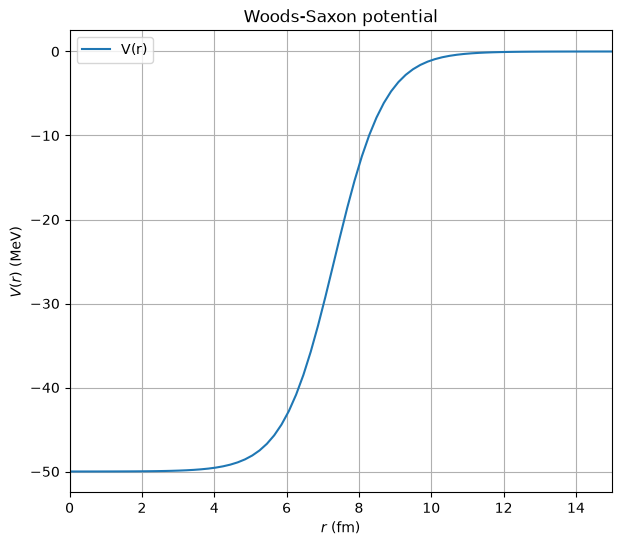

In [2]:
def R(A): 
    "# Nuclear radius (approximate) in fm"
    return 1.25*np.power(A,1./3.) 


def V_WS(r,A,a,V0):
    "Woods-Saxon potential (MeV) felt by a nucleon, arguments: radial distance in fm(r), "
    "nº of nucleons (A), nuclear surface thickness in fm (a), const V_0 in MeV"
    return -V0/(1.0+np.exp((r-R(A))/a))

rplot = np.linspace(0., 20., 100) # array of discrete radial positions to evaluate V_WS and plot
# We use large enough A=200 to get many levels
Vplot = [V_WS(r, 200, 0.7, 50) for r in rplot]

plt.figure(figsize=(7,6))
plt.title(r"Woods-Saxon potential")
plt.plot(rplot,Vplot,label="V(r)")
plt.legend()
plt.xlim([0.,15.])
plt.xlabel("$r$ (fm)")
plt.ylabel("$V(r)$ (MeV)")
plt.grid()

Schrödinger equation to be solved. From
$$ -\frac{\nabla^2}{2 m} \Psi(r) + V(r) \Psi(r) = E \Psi (r)$$
in units $\hbar=c=1$. We make $\Psi(\vec{r})=R(r) Y_{lm} (\theta,\phi)$ and $R(r)= u(r)/r$ to arrive to the equation for the reduced wave function $u(r)$:
$$ -u''(r) + \left( 2 m V(r)  + \frac{l(l+1)}{r^2} \right)u(r)= 2m E u(r)$$
We define
$$ U_{\textrm{eff}}(r) = 2m V(r) + \frac{l(l+1)}{r^2} $$
with units of $1/\text{length}^2$; and $\lambda=2mE$ to give
$$ \left[ -\frac{d^2}{dr^2} + U_{\textrm{eff}} (r) \right] u(r)= \lambda u(r)$$

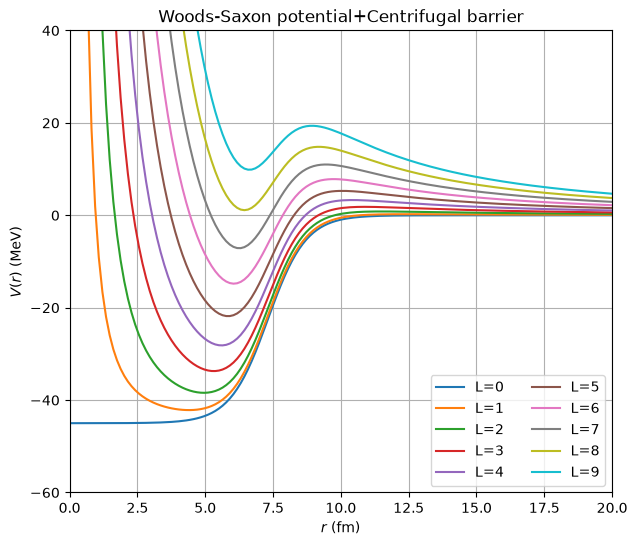

In [3]:
mass = 938.0        # Avg nucleon mass (Mev)
hbarc = 197.328     # (Mev·fm)
mass_fm = mass/hbarc    #mass in fm^(-1) units, is the factor we must add to the potential and eigenvalues in order that the units match!
                        #would come up naturally if we weren't working with atomic units

# Atest is mass number, which should be large enough to get many energy levels
Atest = 200
V0_test = -45.  # Well depth (MeV); negative = attractive
V0_test_fm = V0_test/hbarc  
atest = 0.7  # Skin thickness of the potential

def U_WS_C(r,L,A,a,U0):
    "Woods-Saxon potential plus centrifugal barrier, in fm**-2. U0 = 2*m*V0"
    return U0 / (1.0 + np.exp( (r-R(A))/a ) ) + L*(L + 1.)/r**2

rplot = np.linspace(1e-3, 20., 150)
Lmax = 10

U0test = 2.*mass_fm*V0_test_fm    #In fm**-2

Vplot = [U_WS_C(rplot, L, Atest, atest, U0test)/2./mass_fm*hbarc for L in range(Lmax)]

# Only for plotting: divide it over 2*m and then convert from 1/fm to MeV

plt.figure(figsize=(7, 6))
plt.title(r"Woods-Saxon potential+Centrifugal barrier")

[plt.plot(rplot, Vplot[i], label=f"L={i}") for i in range(Lmax)]

plt.legend(loc='lower right', ncol=2)
plt.ylim([-60.,40.])
plt.xlim([0.0,20.0])
plt.xlabel("$r$ (fm)")
plt.ylabel("$V(r)$ (MeV)")
plt.grid()
plt.show()

### Solution of the Schroedinger Equation. Find eigenvalues of the differential operator

Calling the time-independent Hamiltonian $ {\cal H}= - d^2/dr^2 + U_{\textrm{eff}}(r) $ we need to solve the eigenvalue problem,
$$ {\cal H} \ u(r) = \lambda_n u(r) $$
subjected to boundary conditions $u(0)=u(\infty)=0$.

Numerically, we use **finite differences**
$$ \frac{d^2}{dr^2} u(r)\simeq  \frac{u(r+\Delta r)-2u(r)+u(r-\Delta r)}{\Delta r^2} $$
So that
$$ {\cal H} \ u(r) \simeq \frac{-u(r+\Delta r)}{\Delta r^2} + 2 \frac{u(r)}{\Delta r^2}- \frac{u(r-\Delta r)}{\Delta r^2} + U_{\textrm{eff}} (r) u(r) $$

We discretize $r_i = r_0 + i\,\Delta r$, $i=0,1,\dots,N$, and write $u_i = u(r_i)$. The boundary conditions fix $u_0 = u_N = 0$, so the unknowns are only the interior values $u_1,\dots,u_{N-1}$. Since $u_0=u_N=0$, the terms $-u_0/\Delta r^2$ and $-u_N/\Delta r^2$ simply drop out of the first and last equations.

The Hamiltonian is then represented by an $(N-1)\times(N-1)$ **tridiagonal** matrix, with diagonal entries
$$ \mathcal{H}_{ii} = \frac{2}{\Delta r^2} + U_{\textrm{eff}}(r_i) $$
and entries just above and below the diagonal
$$ \mathcal{H}_{i,i\pm1} = -\frac{1}{\Delta r^2} , $$
so that the eigenvalue problem reads
$$
\begin{pmatrix}
\frac{2}{\Delta r^2} + U_{\textrm{eff}}(r_1) & -\frac{1}{\Delta r^2} & 0 & \cdots & 0 \\
-\frac{1}{\Delta r^2} & \frac{2}{\Delta r^2} + U_{\textrm{eff}}(r_2) & -\frac{1}{\Delta r^2} & \cdots & 0 \\
0 & -\frac{1}{\Delta r^2} & \frac{2}{\Delta r^2} + U_{\textrm{eff}}(r_3) & \ddots & \vdots \\
\vdots & \vdots & \ddots & \ddots & -\frac{1}{\Delta r^2} \\
0 & 0 & \cdots & -\frac{1}{\Delta r^2} & \frac{2}{\Delta r^2} + U_{\textrm{eff}}(r_{N-1})
\end{pmatrix}
\begin{pmatrix} u_1 \\ u_2 \\ u_3 \\ \vdots \\ u_{N-1} \end{pmatrix}
= \lambda
\begin{pmatrix} u_1 \\ u_2 \\ u_3 \\ \vdots \\ u_{N-1} \end{pmatrix} .
$$
The matrix is real and symmetric, so its eigenvalues $\lambda_n$ are real and its eigenvectors orthogonal. We can therefore use a symmetric tridiagonal eigensolver (`eigh_tridiagonal`).

The outer boundary condition $u(r_N)=0$ at $r_N = r_f = 50$ fm acts as an infinite wall. Bound states ($E<0$) decay exponentially well before reaching the wall and are unaffected by it, whereas the continuum ($E>0$) becomes a discrete set of box states. We therefore keep only negative eigenvalues.


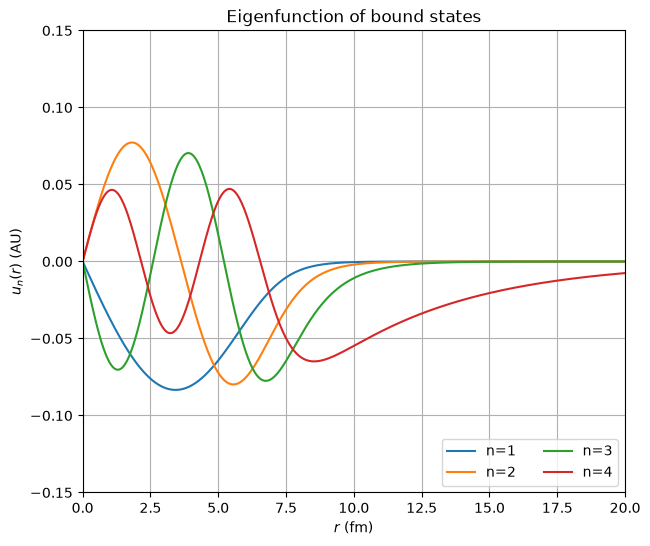

In [4]:
Nr = 2000  # Discretizaton points
ri = 1e-3  # Initial position
rf = 50.0  # Final position
dr = (rf-ri)/Nr  # \Delta r

rvec  = np.linspace(ri, rf, Nr+1)

# Let us start with L=0

#Hamiltonian diagonal
d = 2./dr**2 + U_WS_C(rvec, 0, Atest, atest, U0test)[1:-1] #Remove first and last value of r
# Hamiltonian upper and lower diagonal (does not depend on l, reusable)
e = -1./dr**2 * np.ones(len(d)-1) 

# Diagonalize
eigenvalues_fm,eigenstates = eigh_tridiagonal(d,e)

# Energies in 1/fm (after diving by 2m) back to MeV energies
energies = eigenvalues_fm/2./mass_fm*hbarc

# Count number of bound states
bound_st=0
for i in range(len(energies)):
    if energies[i] < 0: bound_st += 1

# wave functions of bound states
bound_wf = [[] for _ in range(bound_st)]

plt.figure(figsize=(7, 6))
plt.title(r"Eigenfunction of bound states")

for i in range(bound_st):
    bound_wf[i] = np.append(np.insert(eigenstates.T[i], 0, 0.0), 0.0)  #Add u(n_0)=0 and U(r_N)=0
    plt.plot(rvec,bound_wf[i],label=f"n={i+1}")

plt.legend(loc='lower right', ncol=2)
plt.ylim([-0.15,0.15])
plt.xlim([0.0,20.0])
plt.xlabel("$r$ (fm)")
plt.ylabel(r"$u_n(r)$ (AU)")
plt.grid()
plt.show()

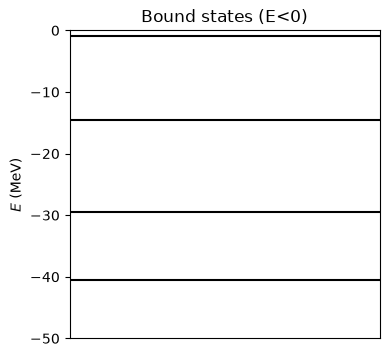

In [5]:
# Plot the energy levels
plt.figure(figsize=(4, 4))
plt.title(r"Bound states (E<0)")
[plt.axhline(y=energies[i], linestyle='-',color='black') for i in range(bound_st)]
plt.ylim([-50.,0.])
plt.xlim([0.0,1.0])
plt.xticks([])
plt.ylabel(r"$E$ (MeV)")
plt.show()

#### Normalization of wave functions
$$ \int d^3r \ |\Psi(r)|^2 = 1 \Rightarrow \int_0^\infty dr \ u(r)^2 = 1 $$

In [6]:
for i in range(bound_st):
    bound_wf[i] = bound_wf[i]/np.sqrt(integrate.simpson(bound_wf[i]**2,rvec))

# We can make sure that wf with different n are orthogonal, and with same n are now normalised
for i in range(bound_st):
    for j in range(bound_st):
        print(i, j, integrate.simpson(bound_wf[i]*bound_wf[j],rvec))



0 0 0.9999999999999998
0 1 -2.5795110857468945e-15
0 2 1.8416383930973102e-16
0 3 -4.570264429785409e-17
1 0 -2.5795110857468945e-15
1 1 1.0000000000000004
1 2 -2.2692902409282698e-15
1 3 -1.0062355940268931e-16
2 0 1.8416383930973102e-16
2 1 -2.2692902409282698e-15
2 2 1.0
2 3 -2.061636344068236e-15
3 0 -4.570264429785409e-17
3 1 -1.0062355940268931e-16
3 2 -2.061636344068236e-15
3 3 1.0


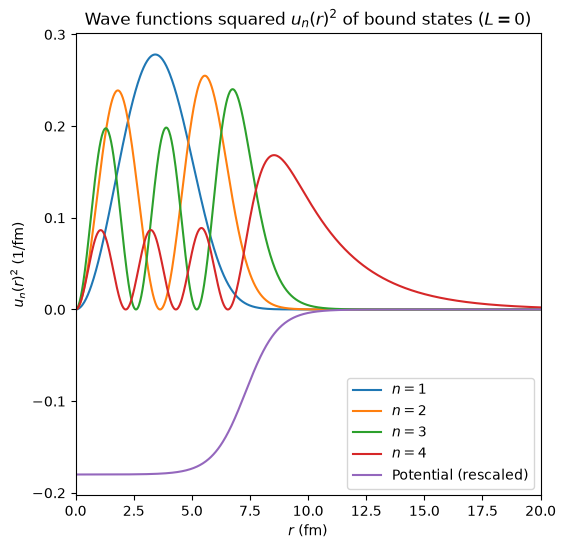

In [7]:
plt.figure(1,figsize=(6, 6))
plt.title(r"Wave functions squared $u_{n}(r)^2$ of bound states ($L=0$)")
#Plot the wfs
[plt.plot(rvec,bound_wf[i]**2,label=f"$n=${i+1}")  for i in range(bound_st)]
#rescale the WS potential by hand in order for it to be in the same plot
plt.plot(rvec,0.004*U_WS_C(rvec,0,Atest, atest, U0test)/2./mass_fm*hbarc,label=r"Potential (rescaled)")

plt.legend(loc='lower right')
#plt.yscale('log')
#plt.ylim([-0.5,0.5])
plt.xlim([0.0,20])
plt.xlabel("$r$ (fm)")
plt.ylabel(r"$u_{n}(r)^{2}$ (1/fm)")
#plt.grid()
plt.show()


### Now we repeat for all $l$, and order all the obtained eigenvalues

In [8]:
energies_final = []  # This vector will store all energies of the bound states found
L_final = []  # This will contain the associated L, for each one of the previous

for L in range(Lmax):
    d = 2./dr**2 + U_WS_C(rvec, L, Atest, atest, U0test)[1:-1]
    #Off diagonal part of the Hamiltonian does not change with l
    eigenvalues_fm, eigenstates = eigh_tridiagonal(d,e)
    energies = eigenvalues_fm/2./mass_fm*hbarc

    # We store energies of bound states as a function of L
    for i in range(len(energies)):
        if  energies[i] < 0.:
            energies_final.append(energies[i])
            L_final.append(L)

In [9]:
# This cell is to print in an ordered way all the negative eigenvalues
sorted_lists = sorted(zip(energies_final, L_final))
ener_sorted, L_sorted = zip(*sorted_lists)
ener_sorted = list(ener_sorted)
L_sorted = list(L_sorted)

print ("L | Energy(MeV)")
print ("---------------")
for i in range(len(L_sorted)):
    print(L_sorted[i], '|', f"{ener_sorted[i]:.3f}")


L | Energy(MeV)
---------------
0 | -40.575
1 | -36.313
2 | -31.211
0 | -29.436
3 | -25.389
1 | -22.753
4 | -18.941
2 | -15.722
0 | -14.583
5 | -11.962
3 | -8.530
1 | -7.182
6 | -4.555
4 | -1.481
0 | -0.832
2 | -0.780


The highest $l$ with a bound state is $l$ = 6 (1i). $l = 7-9$ have none: the centrifugal barrier lifts the effective well above zero.

In [10]:
count = np.zeros(7)  # We used up to l=6, which is the maximum value of l it is found
# We assign the orbital for each value of l
wavelist=['s','p','d','f','g','h','i']
# We assign level degeneracies
deglist =[2,6,10,14,18,22,26]

# counter of states available
cumulative = 0

print("Levels \t Energy(MeV) \t Level Degeneracy \t Total")
print("------------------------------------------------------")
for i in range(len(L_sorted)):
    L = L_sorted[i]
    count[L] += 1  # This will be the principal quantum number
    cumulative +=deglist[L]  # This will count of cumulative degeneracies
    print(f"  {int(count[L])}{wavelist[L]} \t   {ener_sorted[i]:.3f}  \t       {deglist[L]} \t          {cumulative}")



Levels 	 Energy(MeV) 	 Level Degeneracy 	 Total
------------------------------------------------------
  1s 	   -40.575  	       2 	          2
  1p 	   -36.313  	       6 	          8
  1d 	   -31.211  	       10 	          18
  2s 	   -29.436  	       2 	          20
  1f 	   -25.389  	       14 	          34
  2p 	   -22.753  	       6 	          40
  1g 	   -18.941  	       18 	          58
  2d 	   -15.722  	       10 	          68
  3s 	   -14.583  	       2 	          70
  1h 	   -11.962  	       22 	          92
  2f 	   -8.530  	       14 	          106
  3p 	   -7.182  	       6 	          112
  1i 	   -4.555  	       26 	          138
  2g 	   -1.481  	       18 	          156
  4s 	   -0.832  	       2 	          158
  3d 	   -0.780  	       10 	          168


### Do we observe magic numbers (2, 8, 20, 28, 50, 82, and 126)?

We observe the first three magic numbers, 2, 8 and 20 (bigger energy gaps -> closed shell), but after that they are all different from the magic numbers found experimentally.

### We add now a **spin-orbit** term proposed by Goeppert-Mayer, Haxel, Suess, and Jensen to the Hamiltonian
$$ V_{\rm SO}(r) = C_{\rm eff}\,\frac{1}{r}\frac{dV_{\rm WS}}{dr}\,\vec L\cdot\vec S ,
\qquad \langle \vec L\cdot\vec S\rangle = \tfrac12\left[J(J+1)-L(L+1)-\tfrac34\right],$$
with $C_{\rm eff}$ in fm $^2$. Multiplying by $2m$, as in the reduced equation:
$$ U_{\rm SO}(r) = C_{\rm eff}\,\frac{1}{2r}\frac{dU_{\rm WS}}{dr}\left[J(J+1)-L(L+1)-\tfrac34\right].$$
In the code, `U_WS_C_SO` multiplies the spin–orbit term by $2m$ once more, so its argument is `CSO` $= C_{\rm eff}/2m$ (see the note on units below). 

Each $L>0$ level splits into $J = L\pm\tfrac12$.


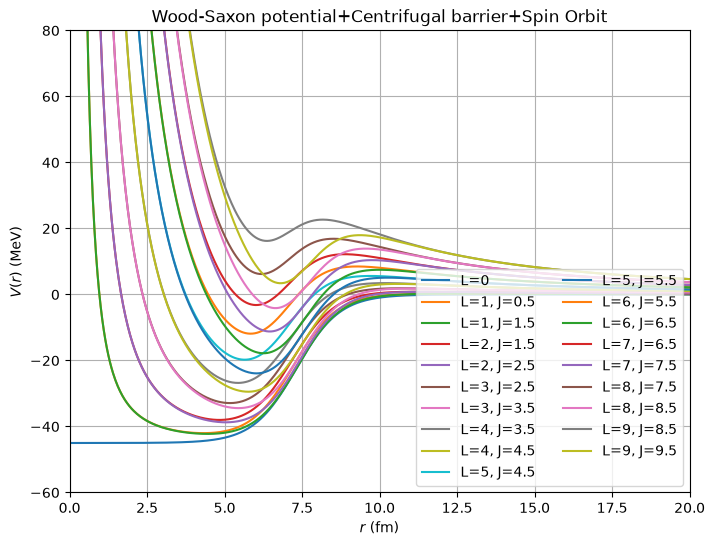

In [11]:
# Woods-Saxon, plus centrifugal barrier, plus spin orbit term
def U_WS_C_SO(r,L,J,A,a,U0,CSO):
    
    U_WS = U0/(1.0 + np.exp((r-R(A))/a))
    U_C = L*(L+1.)/r**2
    dU_WS_dr = - (U0/a)*(np.exp((r - R(A))/a))/(1 + np.exp((r - R(A))/a))**2
    
    return   U_WS + U_C + 2.0*mass_fm*(CSO*(dU_WS_dr)/r)*0.5*(J*(J+1.) - L*(L+1.) - 0.75)# HERE IT GOES THE NEW POTENTIAL WOODS-SAXON + CENTRIFUGAL + SPIN ORBIT! #In 1/fm**2

VplotP = [[] for _ in range(Lmax)]
VplotM = [[] for _ in range(Lmax)]

Ceff_target = -0.71                    # fm^2, ≈ -0.44 r0^2 (Bohr & Mottelson), r0 = 1.27 fm
CSOtest = Ceff_target/(2.0*mass_fm)    # = -0.0747; U_WS_C_SO multiplies by 2m again

# Plot potentials to see the effect of spin-orbit term
for L in range(Lmax):
    if L==0 :
        J = 0.5
        VplotP[L] = [U_WS_C_SO(r, L, J, Atest, atest, U0test,CSOtest)/2./mass_fm*hbarc for r in rvec]
    else:
        J = L-0.5
        VplotM[L] = [U_WS_C_SO(r, L, J, Atest, atest, U0test,CSOtest)/2./mass_fm*hbarc for r in rvec]
        J = L+0.5
        VplotP[L] = [U_WS_C_SO(r, L, J, Atest, atest, U0test,CSOtest)/2./mass_fm*hbarc for r in rvec]


plt.figure(figsize=(8, 6))
plt.title(r"Wood-Saxon potential+Centrifugal barrier+Spin Orbit")


for L in range(Lmax):
    if L==0 :
        J = 0.5
        plt.plot(rvec, VplotP[L], label=f"L=0")
    else:
        J = L-0.5
        plt.plot(rvec, VplotM[L], label=f"L={L}, J={L-0.5}")
        J = L-0.5
        plt.plot(rvec, VplotP[L], label=f"L={L}, J={L+0.5}")

plt.legend(loc='lower right', ncol=2)
plt.ylim([-60.,80.])
plt.xlim([0.0,20.0])
plt.xlabel("$r$ (fm)")
plt.ylabel("$V(r)$ (MeV)")
plt.grid()
plt.show()

In [12]:
energies_final = []
L_final = []
J_final = []
bound_wf = []

bound_st = 0

# We run over L and J, and store only the energies of bound states, keeping their value of L and J
for L in range(Lmax):
    if L==0 :
        J = 0.5
        d = 2./dr**2+U_WS_C_SO(rvec, L,J, Atest, atest, U0test, CSOtest)[1:-1]   # only d changes, not e
        eigenvalues_fm, eigenstates = eigh_tridiagonal(d,e)
        energies = eigenvalues_fm/2./mass_fm*hbarc

        for i in range(len(energies)):
            if  energies[i] < 0.:
                bound_st += 1
                energies_final.append(energies[i])
                bound_wf.append(np.append(np.insert(eigenstates.T[i], 0, 0.0), 0.0))  # Add phi(0)=0 and phi(N+1)=0
                L_final.append(L)
                J_final.append(J)

    else:
        for jj in range(0,2):
            J = L-0.5+jj
            d = 2./dr**2+U_WS_C_SO(rvec, L,J, Atest, atest, U0test,CSOtest)[1:-1]  # only d changes, not e
            eigenvalues_fm, eigenstates = eigh_tridiagonal(d,e)
            energies = eigenvalues_fm/2./mass_fm*hbarc

            for i in range(len(energies)):
                if  energies[i] < 0.:
                    bound_st += 1
                    energies_final.append(energies[i])
                    bound_wf.append(np.append(np.insert(eigenstates.T[i], 0, 0.0), 0.0))  # Add phi(0)=0 and phi(N+1)=0
                    L_final.append(L)
                    J_final.append(J)

print ('No. of bound states found', bound_st)

No. of bound states found 28


## Plot eigenstates after normalization

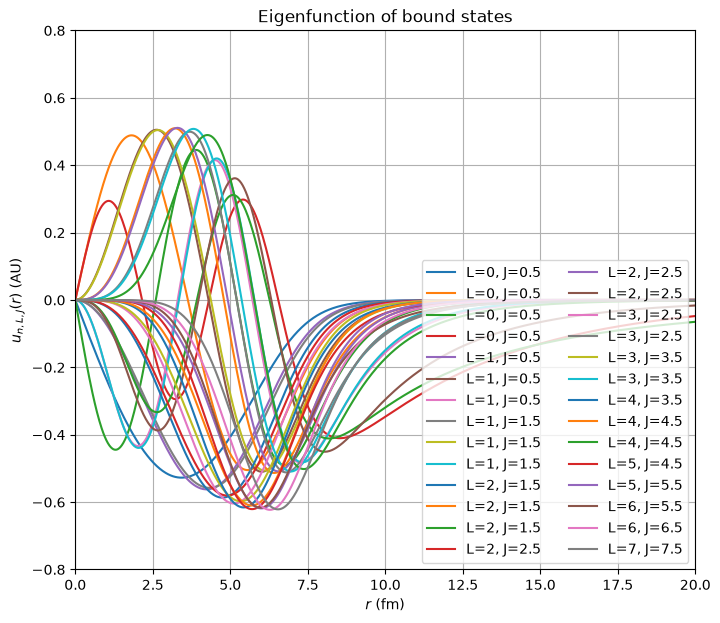

In [13]:
plt.figure(figsize=(8, 7))
plt.title(r"Eigenfunction of bound states")

for i in range(bound_st):
# Normalization of wave function.  int_0^infty u(r)^2 dr = 1
    bound_wf[i] = bound_wf[i]/np.sqrt(integrate.simpson(bound_wf[i]**2,rvec))
    plt.plot(rvec,bound_wf[i],label=f"L={L_final[i]}, J={J_final[i]}")

plt.legend(loc='lower right', ncol=2)
plt.ylim([-0.8,0.8])
plt.xlim([0.0,20.0])
plt.xlabel("$r$ (fm)")
plt.ylabel(r"$u_{n,L,J}(r)$ (AU)")
plt.grid()
plt.show()

In [14]:
# We order the energies and keep track of their L and J
sorted_lists = sorted(zip(energies_final, L_final,J_final))
ener_sorted, L_sorted, J_sorted = zip(*sorted_lists)
ener_sorted = list(ener_sorted)
L_sorted    = list(L_sorted)
J_sorted    = list(J_sorted)

print ('L | J   | Energy(MeV)')
print ('---------------------')
for i in range(len(L_sorted)):
    print (L_sorted[i],'|',J_sorted[i],'| ', f"{ener_sorted[i]:.3f}")


L | J   | Energy(MeV)
---------------------
0 | 0.5 |  -40.575
1 | 1.5 |  -36.459
1 | 0.5 |  -36.031
2 | 2.5 |  -31.644
2 | 1.5 |  -30.600
0 | 0.5 |  -29.436
3 | 3.5 |  -26.250
3 | 2.5 |  -24.316
1 | 1.5 |  -23.026
1 | 0.5 |  -22.213
4 | 4.5 |  -20.367
4 | 3.5 |  -17.280
2 | 2.5 |  -16.365
2 | 1.5 |  -14.764
0 | 0.5 |  -14.583
5 | 5.5 |  -14.065
5 | 4.5 |  -9.599
3 | 3.5 |  -9.583
1 | 1.5 |  -7.496
6 | 6.5 |  -7.405
3 | 2.5 |  -7.115
1 | 0.5 |  -6.548
4 | 4.5 |  -2.873
6 | 5.5 |  -1.413
2 | 2.5 |  -1.262
0 | 0.5 |  -0.832
7 | 7.5 |  -0.453
2 | 1.5 |  -0.111


In [15]:
# We again repeat counting using the usual notation and computing cumulative number of degeneracies
count = np.ones(10)
wavelist=['s','p','d','f','g','h','i','j','k','l']

deg = np.zeros(len(ener_sorted))

for i in range(len(ener_sorted)):
    deg[i] = 1+int(J_sorted[i]*2)  #The degeneracy now depends on J only


cumulative=0


print('Levels \t Energy(MeV) \t Level Degeneracy \t Total')
print('------------------------------------------------------')

for i in range(len(L_sorted)):
    L = L_sorted[i]
    cumulative +=deg[i]
    print ( str(int(count[L]))+wavelist[L]+str(int(J_sorted[i]*2))+'/2'+'\t   '+str(f"{ener_sorted[i]:.2f}" )+'\t       '+ \
           str(int(deg[i])) + '\t           '+ str(int(cumulative)) )
    if J_sorted[i]==abs(L-0.5):
        count[L] += 1  #We increase the principal quantum number, only when the values with smaller J appears, since there are two states for a given nL combination


Levels 	 Energy(MeV) 	 Level Degeneracy 	 Total
------------------------------------------------------
1s1/2	   -40.58	       2	           2
1p3/2	   -36.46	       4	           6
1p1/2	   -36.03	       2	           8
1d5/2	   -31.64	       6	           14
1d3/2	   -30.60	       4	           18
2s1/2	   -29.44	       2	           20
1f7/2	   -26.25	       8	           28
1f5/2	   -24.32	       6	           34
2p3/2	   -23.03	       4	           38
2p1/2	   -22.21	       2	           40
1g9/2	   -20.37	       10	           50
1g7/2	   -17.28	       8	           58
2d5/2	   -16.37	       6	           64
2d3/2	   -14.76	       4	           68
3s1/2	   -14.58	       2	           70
1h11/2	   -14.06	       12	           82
1h9/2	   -9.60	       10	           92
2f7/2	   -9.58	       8	           100
3p3/2	   -7.50	       4	           104
1i13/2	   -7.40	       14	           118
2f5/2	   -7.12	       6	           124
3p1/2	   -6.55	       2	           126
2g9/2	   -2.87	       10	           1

# Do we observe magic numbers (2, 8, 20, 28, 50, 82, and 126)?

Yes, we can observe all the magic numbers are the energy levels where we have the larger energy gap between those and the next level, creating what we call, a closed shell.

# Figures and tables for the report
The cells below reuse the functions and parameters defined above (grid `rvec`, `dr`, `U_WS_C`, `U_WS_C_SO`, `Atest`, `atest`, `U0test`, `CSOtest`, `Lmax`). Figure 1 is saved in `figures/`.

### Step 1: reusable solver
`solve_levels(CSO)` returns the bound levels $(n,l,j,E)$, with $n$ counted per $(l,j)$ and $j=l\pm1/2$. For $C_{\rm SO}=0$ the two $j$ partners are exactly degenerate, and `merge_nl` merges them back into $nl$ levels with degeneracy $2(2l+1)$.

In [16]:
# ---------------------------------------------------------------------------
# Reusable solver: bound single-particle levels (n, l, j, E) for a given C_SO
# ---------------------------------------------------------------------------

wavelist = ['s','p','d','f','g','h','i','j','k','l']

def solve_levels(CSO, A=Atest, a=atest, U0=U0test, Lmax=Lmax, U_func=None):
    """Bound levels of WS + centrifugal + spin-orbit, as a list of (n, l, j, E_MeV)
    sorted by energy. n is the radial quantum number counted per (l, j), starting at 1.
    U_func(r, L, J, A, a, U0, CSO) defaults to U_WS_C_SO (same grid rvec, dr as above)."""
    if U_func is None:
        U_func = U_WS_C_SO
    e_off = -1./dr**2*np.ones(len(rvec)-3)          # off-diagonal (same as e above)
    levels = []
    for L in range(Lmax):
        Jlist = [0.5] if L == 0 else [L+0.5, L-0.5]
        for J in Jlist:
            d_diag = 2./dr**2 + U_func(rvec, L, J, A, a, U0, CSO)[1:-1]
            lam = eigh_tridiagonal(d_diag, e_off, eigvals_only=True)   # sorted ascending
            E = lam/2./mass_fm*hbarc
            for n, En in enumerate(E[E < 0.], start=1):
                levels.append((n, L, J, En))
    return sorted(levels, key=lambda lev: lev[3])

def merge_nl(levels, tol=1e-9):
    """For CSO = 0 the j = l +/- 1/2 partners are exactly degenerate: merge them into
    nl levels. Returns a list of (n, l, E_MeV, deg) with deg = 2(2l+1)."""
    groups = {}
    for n, l, j, E in levels:
        groups.setdefault((n, l), []).append(E)
    out = []
    for (n, l), Es in groups.items():
        assert np.ptp(Es) < tol, f"{n}{wavelist[l]}: j-partners not degenerate (CSO != 0?)"
        out.append((n, l, Es[0], 2*(2*l+1)))
    return sorted(out, key=lambda lev: lev[2])

# Labels
def lab_nl(n, l):     return f"{n}{wavelist[l]}"
def lab_nlj(n, l, j): return f"{n}{wavelist[l]}{int(round(2*j))}/2"
def tex_nlj(n, l, j): return rf"${n}{wavelist[l]}_{{{int(round(2*j))}/2}}$"

def gap_table(levels, merge=False):
    """DataFrame with level label, E (MeV), degeneracy, cumulative N and the gap
    Delta E (MeV) to the next level (NaN for the last bound level)."""
    if merge:
        rows = [(lab_nl(n, l), E, deg) for n, l, E, deg in merge_nl(levels)]
    else:
        rows = [(lab_nlj(n, l, j), E, int(round(2*j+1))) for n, l, j, E in levels]
    df = pd.DataFrame(rows, columns=['level', 'E_MeV', 'deg'])
    df['N_cum'] = df['deg'].cumsum()
    df['gap_MeV'] = df['E_MeV'].shift(-1) - df['E_MeV']
    return df

In [17]:
# Check: solve_levels reproduces the tables printed above
lev_nlj0 = solve_levels(0.0)          # WS + centrifugal (each nl appears twice, j = l +/- 1/2) CSO = 0
lev_nl   = merge_nl(lev_nlj0)         # merged back into nl levels
lev_so   = solve_levels(CSOtest)      # WS + centrifugal + spin-orbit

# Reference 1: the original WS + centrifugal loop (U_WS_C, no spin-orbit at all)
ref0 = []
for LL in range(Lmax):
    dd = 2./dr**2 + U_WS_C(rvec, LL, Atest, atest, U0test)[1:-1]
    ev = eigh_tridiagonal(dd, -1./dr**2*np.ones(len(dd)-1), eigvals_only=True)/2./mass_fm*hbarc
    ref0 += list(ev[ev < 0.])
ref0 = np.sort(ref0)
print("WS+C   : %d nl levels (reference %d), max |dE| = %.1e MeV"
      % (len(lev_nl), len(ref0), np.max(np.abs(np.array([lv[2] for lv in lev_nl]) - ref0))))

# Reference 2: the spin-orbit energies of the original loop (ener_sorted, cell above)
print("WS+C+SO: %d nlj levels (reference %d), max |dE| = %.1e MeV"
      % (len(lev_so), len(ener_sorted), np.max(np.abs(np.array([lv[3] for lv in lev_so]) - np.array(ener_sorted)))))

print("\nLevel  E(MeV)   deg  N        |  Level    E(MeV)  deg  N")
t0, t1 = gap_table(lev_nlj0, merge=True), gap_table(lev_so)
for i in range(max(len(t0), len(t1))):
    left = f"{t0.level[i]:5s} {t0.E_MeV[i]:8.3f} {t0.deg[i]:4d} {t0.N_cum[i]:4d}" if i < len(t0) else " "*23
    right = f"{t1.level[i]:7s} {t1.E_MeV[i]:8.3f} {t1.deg[i]:3d} {t1.N_cum[i]:4d}" if i < len(t1) else ""
    print(left, "    | ", right)

WS+C   : 16 nl levels (reference 16), max |dE| = 0.0e+00 MeV
WS+C+SO: 28 nlj levels (reference 28), max |dE| = 2.4e-10 MeV

Level  E(MeV)   deg  N        |  Level    E(MeV)  deg  N
1s     -40.575    2    2     |  1s1/2    -40.575   2    2
1p     -36.313    6    8     |  1p3/2    -36.459   4    6
1d     -31.211   10   18     |  1p1/2    -36.031   2    8
2s     -29.436    2   20     |  1d5/2    -31.644   6   14
1f     -25.389   14   34     |  1d3/2    -30.600   4   18
2p     -22.753    6   40     |  2s1/2    -29.436   2   20
1g     -18.941   18   58     |  1f7/2    -26.250   8   28
2d     -15.722   10   68     |  1f5/2    -24.316   6   34
3s     -14.583    2   70     |  2p3/2    -23.026   4   38
1h     -11.962   22   92     |  2p1/2    -22.213   2   40
2f      -8.530   14  106     |  1g9/2    -20.367  10   50
3p      -7.182    6  112     |  1g7/2    -17.280   8   58
1i      -4.555   26  138     |  2d5/2    -16.365   6   64
2g      -1.481   18  156     |  2d3/2    -14.764   4   68
4s     

**Note on units.** In `U_WS_C_SO` the spin–orbit term carries an extra factor `2.0*mass_fm`, although $U_{\rm WS}=2mV_{\rm WS}$ already contains $2m$. The physical constant multiplying $\frac{1}{r}\frac{dV_{\rm WS}}{dr}\langle\vec l\cdot\vec s\rangle$ is therefore $C_{\rm eff}=2m\,C_{\rm SO}$ (in fm$^2$). We fix $C_{\rm eff}=-0.71$ fm$^2$, i.e. `CSOtest` $=C_{\rm eff}/2m=-0.0747$; the cell below prints $C_{\rm eff}$ and two representative splittings.

In [18]:
# Effective spin-orbit constant and two representative splittings
Ceff_test = 2.0*mass_fm*CSOtest      # fm^2
Eso = {(n, l, j): E for n, l, j, E in solve_levels(CSOtest)}
print(f"C_eff = 2 m C_SO = {Ceff_test:.3f} fm^2")
print(f"1p1/2 - 1p3/2 splitting = {Eso[(1,1,0.5)] - Eso[(1,1,1.5)]:.3f} MeV")
print(f"1h9/2 - 1h11/2 splitting = {Eso[(1,5,4.5)] - Eso[(1,5,5.5)]:.3f} MeV")

C_eff = 2 m C_SO = -0.710 fm^2
1p1/2 - 1p3/2 splitting = 0.428 MeV
1h9/2 - 1h11/2 splitting = 4.466 MeV


### Step 2: correlation diagram (Figure 1)
Harmonic oscillator ($\hbar\omega=41A^{-1/3}$ MeV, shifted so that $N=0$ coincides with the WS $1s$ level), then Woods–Saxon + centrifugal, then + spin–orbit. In each column the cumulative nucleon number is written in every gap larger than 2 MeV. In the third column the real magic numbers are boxed, whatever their gap. Note that the shifted HO $N=6$ shell lies at $+1.5$ MeV, just above threshold, although all of its WS levels are bound. The spin–orbit term also binds the $1j_{15/2}$ intruder (above 126), whose $1j$ parent is unbound in the central potential: its connector comes down from the continuum, labelled "1j (unbound)".

hbar*omega = 7.011 MeV, HO shift = -51.092 MeV


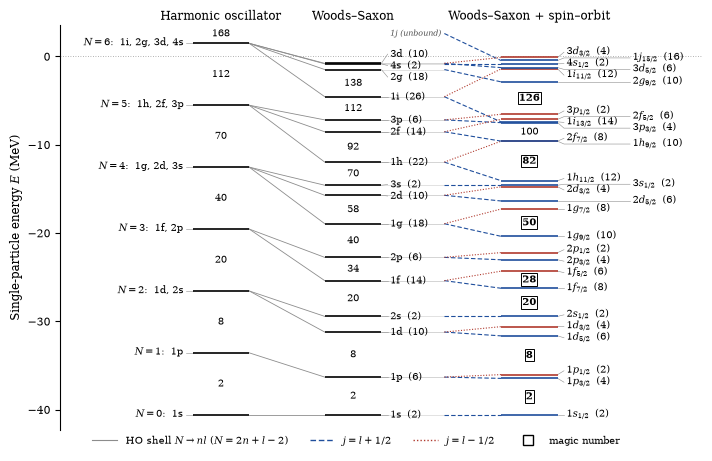

In [19]:
# ---------------------------------------------------------------------------
# Figure 1: correlation diagram   HO  ->  WS + centrifugal  ->  WS + centrifugal + SO
# ---------------------------------------------------------------------------

os.makedirs('figures', exist_ok=True)

MAGIC = [2, 8, 20, 28, 50, 82, 126]
GAP_MIN = 2.0                       # MeV: gaps larger than this get their cumulative N written
C_UP, C_DN = '#1f4e9c', '#b03a2e'   # j = l+1/2 / j = l-1/2 (also distinguished by linestyle)

def spread_labels(y, sep):
    """Label positions as close as possible to y with a minimum spacing sep
    (overlapping labels are merged into clusters centred on their mean)."""
    y = np.asarray(y, float)
    order = np.argsort(y)
    ys = y[order]
    clusters = [[k] for k in range(len(ys))]
    pos = lambda c: ys[c].mean() + sep*(np.arange(len(c)) - 0.5*(len(c)-1))
    i = 0
    while i < len(clusters)-1:
        if pos(clusters[i])[-1] + sep > pos(clusters[i+1])[0] + 1e-9:
            clusters[i] += clusters.pop(i+1)
            i = max(i-1, 0)          # the merged cluster may now overlap the one below
        else:
            i += 1
    out = np.empty_like(y)
    out[order] = np.concatenate([pos(c) for c in clusters])
    return out

# --- data -----------------------------------------------------------------
lev_nl = merge_nl(solve_levels(0.0))                 # (n, l, E, deg)
lev_so = solve_levels(CSOtest)                       # (n, l, j, E)
E_nl = {(n, l): E for n, l, E, deg in lev_nl}

# 3D harmonic oscillator, hw = 41 A^(-1/3) MeV, shifted so that E_{N=0} = E_WS(1s)
hw = 41.*Atest**(-1./3.)
N_HO = np.arange(7)
shift_HO = E_nl[(1, 0)] - 1.5*hw                     # = -51.09 MeV for A = 200
E_HO = hw*(N_HO + 1.5) + shift_HO                    # note: N = 6 lies at +1.5 MeV (above threshold)
deg_HO = (N_HO + 1)*(N_HO + 2)
df_HO = pd.DataFrame({'E_MeV': E_HO, 'N_cum': np.cumsum(deg_HO)})
df_HO['gap_MeV'] = df_HO['E_MeV'].shift(-1) - df_HO['E_MeV']
print(f"hbar*omega = {hw:.3f} MeV, HO shift = {shift_HO:.3f} MeV")

df_nl, df_so = gap_table(solve_levels(0.0), merge=True), gap_table(lev_so)

# --- layout (x in arbitrary units) ----------------------------------------
X1, X2, X3 = (0.0, 0.9), (2.1, 3.0), (4.9, 5.8)     # level-line extents of the 3 columns
XCONN2 = X2[1] + 1.0                                # WS->SO connectors start after the labels
SEP, FS, FS_N = 1.3, 7, 7.5                         # min label spacing (MeV), font sizes
STAGGER3 = 1.05                                     # x offset of the 2nd label sub-column (col. 3)

def draw_levels(ax, x, Es, labels, side, colors, lw=1.2, stagger=0.0):
    """Level lines plus labels with leader lines. With stagger > 0, label clusters that
    would be pushed far from their levels alternate between two sub-columns (stagger
    apart in x), so neighbouring labels there only need SEP/2 of vertical spacing."""
    Es = np.asarray(Es, float)
    ylab = spread_labels(Es, SEP)
    shift = np.zeros(len(Es))
    if stagger:
        order = np.argsort(ylab)
        clusters, cur = [], [order[0]]
        for a, b in zip(order[:-1], order[1:]):      # runs of labels packed at spacing SEP
            if ylab[b] - ylab[a] < SEP + 1e-6:
                cur.append(b)
            else:
                clusters.append(cur); cur = [b]
        clusters.append(cur)
        for cl in clusters:
            cl = np.array(cl)
            if len(cl) > 1 and np.max(np.abs(ylab[cl] - Es[cl])) > 0.5*SEP:
                ylab[cl] = spread_labels(Es[cl], SEP/2)
                shift[cl[np.argsort(ylab[cl])][1::2]] = stagger
    s = 1 if side == 'right' else -1
    xa = x[1] if side == 'right' else x[0]
    for E, yl, dx, lab, col in zip(Es, ylab, shift, labels, colors):
        ax.plot(x, [E, E], color=col, lw=lw, solid_capstyle='butt', zorder=3)
        ax.plot([xa, xa + 0.10*s, xa + (0.10 + dx)*s], [E, yl, yl], color='0.55', lw=0.4, zorder=2)
        ax.text(xa + (0.14 + dx)*s, yl, lab, ha='left' if s > 0 else 'right', va='center', fontsize=FS)

def annotate_gaps(ax, xc, df, magic=None, label_last=True):
    """Write cumulative N in the middle of every big gap (and, if label_last, above the
    highest level). If magic is given, those N are drawn bold and boxed (whatever their gap)."""
    for i in range(len(df)):
        gap, N = df['gap_MeV'].iloc[i], int(df['N_cum'].iloc[i])
        last = i == len(df) - 1
        is_magic = magic is not None and N in magic
        if last and not label_last:
            continue
        if not (last or gap >= GAP_MIN or is_magic):
            continue
        y = df['E_MeV'].iloc[i] + (1.1 if last else 0.5*gap)
        box = dict(boxstyle='square,pad=0.1', fc='white', ec='black' if is_magic else 'none', lw=0.7)
        ax.text(xc, y, str(N), ha='center', va='center', fontsize=FS_N, zorder=5,
                fontweight='bold' if is_magic else 'normal', bbox=box)

with plt.rc_context({'font.family': 'serif', 'mathtext.fontset': 'dejavuserif',
                     'font.size': 9, 'pdf.fonttype': 42}):
    fig, ax = plt.subplots(figsize=(7.0, 4.5))

    # Column 1: harmonic oscillator shells, labelled by their nl content
    ho_lab = []
    for N in N_HO:
        nls = [lab_nl((N-l)//2 + 1, l) for l in range(N, -1, -2)]
        ho_lab.append(f"$N={N}$:  " + ", ".join(nls))
    draw_levels(ax, X1, E_HO, ho_lab, 'left', ['black']*len(E_HO))
    annotate_gaps(ax, np.mean(X1), df_HO)

    # Column 2: WS + centrifugal, nl levels with degeneracy 2(2l+1)
    draw_levels(ax, X2, [lv[2] for lv in lev_nl],
                [f"{lab_nl(n, l)}  ({deg})" for n, l, E, deg in lev_nl], 'right', ['black']*len(lev_nl))
    annotate_gaps(ax, np.mean(X2), df_nl, label_last=False)

    # Column 3: WS + centrifugal + spin-orbit, nlj levels with degeneracy 2j+1
    cols3 = [C_UP if j > l else C_DN for n, l, j, E in lev_so]
    draw_levels(ax, X3, [lv[3] for lv in lev_so],
                [f"{tex_nlj(n, l, j)}  ({int(2*j+1)})" for n, l, j, E in lev_so], 'right', cols3, stagger=STAGGER3)
    annotate_gaps(ax, np.mean(X3), df_so, magic=MAGIC, label_last=False)

    # Connectors: HO shell N -> nl levels with 2(n-1)+l = N
    for n, l, E, deg in lev_nl:
        N = 2*(n-1) + l
        ax.plot([X1[1], X2[0]], [E_HO[N], E], color='0.55', lw=0.6, ls='-', zorder=1)
    # Connectors: nl -> its two children j = l +/- 1/2.
    # A strong spin-orbit term can bind a j = l+1/2 intruder whose nl parent is unbound
    # in the central potential (C_SO = 0), e.g. 1j15/2: its connector comes down from E > 0.
    Y_CONT = 2.6
    for n, l, j, E in lev_so:
        up = j > l
        E_par = E_nl.get((n, l))
        if E_par is None:
            E_par = Y_CONT
            ax.text(XCONN2 - 0.05, Y_CONT, f"{lab_nl(n, l)} (unbound)", ha='right', va='center',
                    fontsize=FS-1, style='italic', color='0.3')
        else:
            ax.plot([X2[1], XCONN2], [E_par]*2, color='0.8', lw=0.4, zorder=0)
        ax.plot([XCONN2, X3[0]], [E_par, E], color=C_UP if up else C_DN,
                lw=0.8, ls=(0, (4, 2)) if up else (0, (1, 1.5)), zorder=1)

    ax.axhline(0., color='0.6', lw=0.6, ls=(0, (1, 2)), zorder=0)
    ax.set_ylim(-42.3, 3.6)
    ax.set_xlim(-2.1, 8.1)
    ax.set_xticks([])
    ax.tick_params(axis='y', labelsize=8)
    for sp in ['top', 'right', 'bottom']:
        ax.spines[sp].set_visible(False)
    ax.set_ylabel(r"Single-particle energy $E$ (MeV)", fontsize=8.5)
    for x, title in [(X1, "Harmonic oscillator"), (X2, "Woods–Saxon"),
                     (X3, "Woods–Saxon + spin–orbit")]:
        ax.text(np.mean(x), 1.005, title, transform=ax.get_xaxis_transform(),
                ha='center', va='bottom', fontsize=8.5)

    handles = [Line2D([], [], color='0.55', lw=0.8, ls='-', label=r"HO shell $N\to nl$ ($N=2n+l-2$)"),
               Line2D([], [], color=C_UP, lw=1.0, ls=(0, (4, 2)), label=r"$j=l+1/2$"),
               Line2D([], [], color=C_DN, lw=1.0, ls=(0, (1, 1.5)), label=r"$j=l-1/2$"),
               Line2D([], [], ls='none', marker='s', mfc='white', mec='black', ms=7,
                      label="magic number")]
    fig.legend(handles=handles, loc='lower center', ncol=4, frameon=False, fontsize=7.5,
               bbox_to_anchor=(0.5, 0.0), handlelength=2.4)
    fig.tight_layout(rect=(0, 0.05, 1, 1), pad=0.3)
    fig.savefig('figures/fig1_correlation_diagram.pdf')
    fig.savefig('figures/fig1_correlation_diagram.png', dpi=300)
    plt.show()

### Step 3: gap tables
For each model: level, energy, degeneracy, cumulative $N$ and the gap $\Delta E$ to the next level, followed by the largest gaps and, for the spin–orbit model, the gap at each magic number with its rank among all gaps and the two neighbouring gaps.

In [20]:
# ---------------------------------------------------------------------------
# Gap tables: level, E, degeneracy, cumulative N, gap to the next level
# ---------------------------------------------------------------------------
def gap_report(A, n_top=8):
    models = {'WS+C (C_SO=0)': gap_table(solve_levels(0.0, A=A), merge=True),
              'WS+C+SO (C_SO=CSOtest)': gap_table(solve_levels(CSOtest, A=A))}
    for name, df in models.items():
        print(f"\n=== A = {A}: {name} ===")
        print(df.to_string(index=False, float_format=lambda x: f"{x:8.3f}"))
        gaps = df.dropna().sort_values('gap_MeV', ascending=False).reset_index(drop=True)
        gaps.index += 1                                          # rank 1 = largest gap
        print(f"\n  {n_top} largest gaps (closures):")
        print("  " + gaps.head(n_top)[['N_cum', 'level', 'gap_MeV']].to_string(
              float_format=lambda x: f"{x:6.3f}").replace("\n", "\n  "))
        if name.startswith('WS+C+SO'):
            print("\n  Magic numbers:  N   gap(MeV)  rank   [previous gap, next gap]")
            for N in MAGIC:
                hit = df.index[df['N_cum'] == N]
                if len(hit) == 0 or np.isnan(df['gap_MeV'][hit[0]]):
                    print(f"                {N:4d}   not a closure / last level"); continue
                i = hit[0]
                rank = int(gaps.index[gaps['N_cum'] == N][0])
                below = df['gap_MeV'][i-1] if i > 0 else np.nan
                above = df['gap_MeV'][i+1] if i+1 < len(df) else np.nan
                print(f"                {N:4d}   {df['gap_MeV'][i]:6.3f}   {rank:3d}    "
                      f"[{below:5.3f}, {above:5.3f}]")
    return models

gaps_A200 = gap_report(Atest)


=== A = 200: WS+C (C_SO=0) ===
level    E_MeV  deg  N_cum  gap_MeV
   1s  -40.575    2      2    4.263
   1p  -36.313    6      8    5.101
   1d  -31.211   10     18    1.776
   2s  -29.436    2     20    4.047
   1f  -25.389   14     34    2.636
   2p  -22.753    6     40    3.812
   1g  -18.941   18     58    3.219
   2d  -15.722   10     68    1.139
   3s  -14.583    2     70    2.621
   1h  -11.962   22     92    3.432
   2f   -8.530   14    106    1.348
   3p   -7.182    6    112    2.627
   1i   -4.555   26    138    3.074
   2g   -1.481   18    156    0.648
   4s   -0.832    2    158    0.053
   3d   -0.780   10    168      NaN

  8 largest gaps (closures):
     N_cum level  gap_MeV
  1      8    1p    5.101
  2      2    1s    4.263
  3     20    2s    4.047
  4     40    2p    3.812
  5     92    1h    3.432
  6     58    1g    3.219
  7    138    1i    3.074
  8     34    1f    2.636

=== A = 200: WS+C+SO (C_SO=CSOtest) ===
 level    E_MeV  deg  N_cum  gap_MeV
 1s1/2  -40.57